____
# CAT Analysis Pipeline Tutorial
____





#### Getting Started

1. ssh into Derecho/Casper. You will need your password.

   ```bash
   ssh [username]@casper.hpc.ucar.edu

   ```
   <br>
   
3. clone repository
   ```bash
   git clone https://github.com/ai2es/cat-rain.git

   ```
   <br>
   
4. move into the remote git repository you just cloned
   ```bash
   cd cat-rain

   ```
   <br>
   
5. create environment
   ```bash
   conda env create -f environment.yml

   ```
   <br>
   
6. activate environment
   ```bash
   conda activate cat

   ```
   <br>
   
7. Test your environment is set up correctly by sumbitting a demo config. An output/error log will be saved to a file in cat-rain/scripts/ with the filename `cat.o[jobid]`. If the job completed successfully, it will print that on the bottom of the output file.
   ```bash
   cd scripts
   qsub submit_casper_demo.sh

   ```

#### Editing the config file (cat-rain/configs/demo.yaml)

```yaml
base_data_path: "/glade/campaign/cisl/aiml/cat_flood/intermediate_data/chunked_data_2023_2024/"
data_prefix: "veraset"
key_file: "/glade/campaign/cisl/aiml/cat_flood/intermediate_data/2023_2024/key_file/id_row_group_key.parquet"
# home_loc_file: "/glade/work/ggantos/cat-rain/notebooks/home_loc_by_row_group_counties_unfiltered.parquet"
home_loc_file: "/glade/derecho/scratch/cbecker/CAT_home_loc_20251010/home_loc_by_row_group.parquet"
geo_file: "/glade/work/cbecker/california_zip.geojson"
save_out_path: "/glade/derecho/scratch/ggantos/demo_20260521/" FREQUENTLY EDITED
start_date: "2024-03-29" FREQUENTLY EDITED
end_date: "2024-04-01" FREQUENTLY EDITED
days_of_week: "all" # Supports: "MON", "TUE", "WED", "THU", "FRI", "SAT", "SUN" and "all"
row_group_start_end: [1, 5] FREQUENTLY EDITED # empty [] will use all row groups [start, end]
uids_final: null FREQUENTLY EDITED #"/glade/work/ggantos/cat-rain/notebooks/uids_final_counties.pkl"
aggregation_type: "daily" # Supports "full" or "daily"; only applies to non_grouped_calcs
n_workers: 32 #-1 to use all available CPU workers

# (List) Should be keys under the "filters" or "measures"
# Will operate sequentially in the defined order
# Example: ["compress", "uncorrelated_entropy", "radius_of_gyration"]
# Would result in compressing all the data with given args, then calculating the entropy and ROG
# and merging the results. Filters apply one after another on the output of the previous filter result
# Measures are calculated independently on the filter results (if any) and then merged together
pipeline: ["min_pings_per_date_filter", "number_of_visits", "distance_straight_line", "jump_lengths", "radius_of_gyration", "max_distance_from_home_static", "stay_locations_count"] FREQUENTLY EDITED

grouped_analysis:
  use: False # ignores "grouped" calculations if False
  spatial_agg: ["zipcode"]
  temporal_agg: ["date"] # Currently only supports "date"
  stats: ["mean", "median", "sum"]

########### HOME LOCATIONS ##########
home_locations:
  home_location_tao:
      stop_radius_factor: 0.5
      minutes_for_a_stop: 10.0
      spatial_radius_km: 0.2
      leaving_time: True
      no_data_for_minutes: 1000000000000.0
      min_speed_kmh: null
      cluster_radius_km: 0.1
      min_samples: 1

########### FILTERING ##########
filters:
  min_pings_per_date_filter:
    start_date: "2024-03-29"
    end_date: "2024-04-01"
    min_pings: 10

  mobility_filter:
    max_speed_kmh: 200.0
    include_loops: False
    speed_kmh: 5.0
    max_loop: 6
    ratio_max: 0.25

  horizontal_accuracy_and_speed_filter:
    max_horizontal_accuracy: 800
    max_speed_kmh: 128.7

  compress:
    spatial_radius_km: 0.2


########### INDIVIDUAL MEASURES ##########
individual_measures:

  number_of_visits:
    show_progress: False
    
  distance_straight_line:
    show_progress: False
  
  jump_lengths:
    show_progress: False
    merge: False
  
  radius_of_gyration:
    show_progress: False

  waiting_times:
    show_progress: False

  max_distance_from_home_static:
    kwargs: None
    
  stay_locations_count:
    stop_radius_factor: 0.5
    minutes_for_a_stop: 20.0
    spatial_radius_km: 0.2
    leaving_time: False

  real_entropy:
    show_progress: False

  uncorrelated_entropy:
    normalize: False
    show_progress: False

##################### COLLECTIVE METRICS ###############
collective_measures:
  mean_square_displacement:
    days: 0
    hours: 1
    minutes: 0
    show_progress: False

  random_location_entropy:
    show_progress: False

  uncorrelated_location_entropy:
    normalize: False
    show_progress: False
```

#### Running from Terminal

You can use the pbs submit to casper or derecho via the command `qsub submit_casper.sh` or `qsub submit_derecho.sh`. Example below. Note I have one job running (`R`) and one job queued (`Q`). You can also note the job run ID (`3891497`).

![Alt Text](images/qsub.png)


#### Other scripts besides `calc_metrics.py`
Other scripts you can submit with the `qsub submit_casper.sh` or `qsub submit_derecho.sh` commands:

```python
python -u calc_home_location.py -c ../config/calc_home_loc.yaml
python -u calc_uids.py -c ../config/calc_uids.yaml
python -u get_mrms_data.py
python -u calc_mrms.py -c ../config/mrms.yaml
```


#### Files created from running `calc_metrics.py`

In [32]:
! ls -lr /glade/derecho/scratch/ggantos/demo_20260521/

total 4812
-rw-rw-r-- 1 ggantos ncar   13645 May 21 09:52 veraset_2024-04-01_PST_chunked.parquet
-rw-rw-r-- 1 ggantos ncar   13167 May 21 09:52 veraset_2024-03-31_PST_chunked.parquet
-rw-rw-r-- 1 ggantos ncar   12258 May 21 09:52 veraset_2024-03-30_PST_chunked.parquet
-rw-rw-r-- 1 ggantos ncar   14275 May 21 09:52 veraset_2024-03-29_PST_chunked.parquet
-rw-rw-r-- 1 ggantos ncar 4852178 May 21 09:52 Unique_Users.html
-rw-rw-r-- 1 ggantos ncar    5868 May 21 09:52 summary.parquet
-rw-rw-r-- 1 ggantos ncar    2308 May 21 09:51 process_conf.yaml


## What do results look like?

#### First, let's open a jupyter notebook

Start a Jupyter notebook here: https://jupyterhub.hpc.ucar.edu/

Click on **Production**.

![Alt Text](images/production.png)


You will arrive at the server name page where you you can click **start** and name various server types.

![Alt Text](images/server_name.png)


You will have two options. The easiest to schedule is **Casper Login** because you are not asking for HPC resources, just to log into the remote compute service similar to ssh but with a jupyter notebook tunnel.

![Alt Text](images/casper_login.png)


The second option, **Casper Batch**, allows you to request major resources, similar to the `submit_casper.sh` script we submitted above.

![Alt Text](images/casper_batch.png)

There are various options for the configuration of your request and asking for more resources and more time may lead to longer wait times in the queue.

![Alt Text](images/batch_options.png)

#### Now we'll load some files, summarize, and visualize


_________
First we'll get a list of filenames and verify that those files exist.

In [21]:
# import python packages
import os
import pandas as pd
import yaml
import numpy as np
import matplotlib.pyplot as plt


In [2]:
# list and verify analysis data files exist

base_data_path = "/glade/derecho/scratch/ggantos/demo_20260521/"
start_date = "2023-03-29"
end_date = "2024-04-01"

date_range = pd.date_range(start=start_date, end=end_date, freq="d")
data_files = date_range.strftime(
    f"{base_data_path}veraset_%Y-%m-%d_PST_chunked.parquet"
)
files = []
for i, f in enumerate(data_files):
    if os.path.isfile(f):
        files.append(f)

# print the length of the files listed and that exist
print(len(files))

4


____
Load a single file

In [10]:
df = pd.read_parquet(files[0])
print(df.shape)
df.head(10)

(7, 13)


,uid,duration,lat_home,lng_home,zipcode,row_group,number_of_visits,distance_straight_line,jump_lengths,radius_of_gyration,num_stops,max_distance_from_home,date
0,000177147c6e9815b70ed943974a0954b4ceac224477b6...,12 days 04:55:50,35.614240,-117.681561,93555,1,117,3.988908,"[0.004373271150858783, 0.0018766738352517527, ...",0.156325,1,1.697588,2024-03-29
4,000121c6c1a15b28b1762b8ac9e0ee1cc93cb60aac9d58...,12 days 01:51:12,37.731777,-122.443264,94131,1,28,3.710201,"[0.0006709474187840382, 0.10136989488730919, 0...",0.802909,2,2.552477,2024-03-29
8,000101807d2154f7c6bf70ae8f63c77a305e13d47a4eab...,18 days 22:02:45,37.651036,-120.923565,95357,1,33,23.727817,"[0.002925485337399451, 0.002510520489481555, 0...",4.284530,2,11.814919,2024-03-29
0,000250d82c3ff822a767cffb66d7dabd5885257b102607...,8 days 22:59:00,33.749908,-117.907108,92703,2,159,396.075870,"[0.00489423755447267, 0.0, 0.00084834996503901...",5.056274,7,9.317566,2024-03-29
3,0001f3b39c2401699827fae8501a3aeef9b100a7916d06...,15 days 04:22:17,37.222642,-121.880860,95120,2,36,0.227794,"[0.0060945762588547215, 0.0010844549845850854,...",0.004864,1,0.010586,2024-03-29
0,0003536a4ee5fdecf888aba79f27e772093bd14448542b...,25 days 17:41:43,34.034570,-118.127688,91755,3,24,36.262246,"[0.01053463586166675, 0.009017963197661214, 0....",2.705129,4,12.672266,2024-03-29
0,0003e496709237add336cb8040e64661a2911fd12e84f3...,41 days 11:56:17,34.105705,-118.328606,90068,4,503,1.364076,"[0.0025439701378271317, 0.0025439701378271317,...",0.002111,1,0.005186,2024-03-29


____
Summarize that file

In [6]:
df.describe()

,duration,lat_home,lng_home,row_group,number_of_visits,distance_straight_line,radius_of_gyration,num_stops,max_distance_from_home,date
count,7,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7
mean,19 days 05:24:09.142857142,35.729983,-119.613236,2.000000,128.571429,66.479559,1.858878,2.571429,5.438655,2024-03-29 00:00:00
min,8 days 22:59:00,33.749908,-122.443264,1.000000,24.000000,0.227794,0.002111,1.000000,0.005186,2024-03-29 00:00:00
25%,12 days 03:23:31,34.070138,-121.402213,1.000000,30.500000,2.537139,0.080595,1.000000,0.854087,2024-03-29 00:00:00
50%,15 days 04:22:17,35.614240,-118.328606,2.000000,36.000000,3.988908,0.802909,2.000000,2.552477,2024-03-29 00:00:00
75%,22 days 07:52:14,37.436839,-118.017398,2.500000,138.000000,29.995032,3.494830,3.000000,10.566242,2024-03-29 00:00:00
max,41 days 11:56:17,37.731777,-117.681561,4.000000,503.000000,396.075870,5.056274,7.000000,12.672266,2024-03-29 00:00:00
std,11 days 06:14:03.154257222,1.796870,2.056190,1.154701,173.209754,145.973127,2.149495,2.225395,5.617531,NaN


____
Load multiple files and concatenate them together.

In [9]:
df_combined = pd.concat(
    pd.read_parquet(f)
    for f in files)
df_combined.shape

(30, 13)

____
#### Add county names to the combined data

First, load the county zip codes.

In [13]:
with open("../config/zips_counties.yaml", 'r') as stream:
    zips_counties = yaml.load(stream, Loader=yaml.FullLoader)
    zips = [str(z) for z in zips_counties["zips_LA"] + zips_counties["zips_SB"] + zips_counties["zips_VE"]]
zips_dict = {}
for k,v in zips_counties.items():
    for x in v:
        zips_dict[str(x)] = k.split("_")[1]

Now map the zip dictionary to the data.

In [17]:
df_combined["county"] = df_combined["zipcode"].map(zips_dict)
df_gb = df_combined.groupby('county').size()
print(df_gb)

county
LA    11
dtype: int64


____
#### Visualizations

Histogram of the `num_stops` metric.

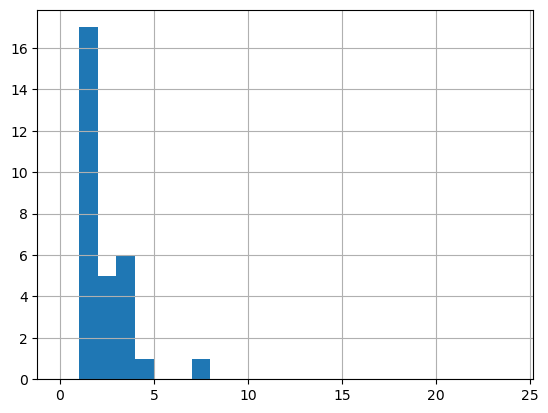

In [31]:
df_combined["num_stops"].hist(bins=np.arange(25))
plt.show()

Visualize a user's change in `max_distance_from_home` over the four day period.

First, which user ID's are available and how many days are they represented in our dataset?

In [26]:
df_combined.groupby("uid").size()

uid
000101807d2154f7c6bf70ae8f63c77a305e13d47a4eab5c019ec0cf11d65c0d    4
000121c6c1a15b28b1762b8ac9e0ee1cc93cb60aac9d58f2630d140adadc6eef    4
000177147c6e9815b70ed943974a0954b4ceac224477b6cf22faefa843b8107b    4
0001f3b39c2401699827fae8501a3aeef9b100a7916d06d78af58586fc00af37    4
000250d82c3ff822a767cffb66d7dabd5885257b1026078b57f9ef2e49b1f07d    3
0003536a4ee5fdecf888aba79f27e772093bd14448542b53372c1ea07add61d0    4
00038b29bf76886b619ec3be4ed1972cc2db5b5287550d3355231a7b744d1798    3
0003e496709237add336cb8040e64661a2911fd12e84f3dac3a14b1cf3acd13b    4
dtype: int64

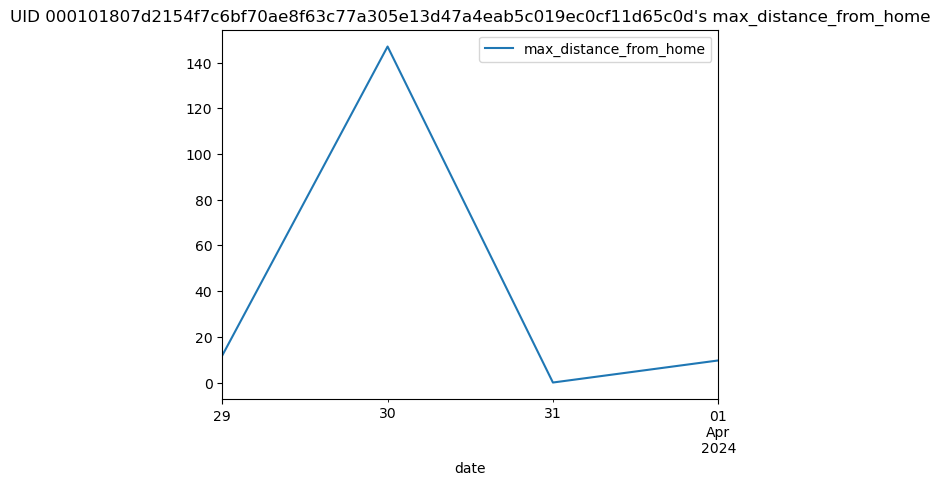

In [30]:
uid = "000101807d2154f7c6bf70ae8f63c77a305e13d47a4eab5c019ec0cf11d65c0d"
var = "max_distance_from_home"

df_combined[df_combined["uid"]==uid].plot("date", var,
                                          kind='line',
                                          title=f"UID {uid}'s {var}")
plt.show()

### Resources

scikit-mobility documentation: https://scikit-mobility.github.io/scikit-mobility/

scikit-mobility repository: https://github.com/scikit-mobility/scikit-mobility

ai2es/cat-rain repository: https://github.com/ai2es/cat-rain

commonly used pbs commands: https://www.nas.nasa.gov/hecc/support/kb/commonly-used-pbs-commands_174.html